# Launch health of Polish-made games on Steam

**The question, from a publisher's head of publishing:** *What does a healthy first 90 days on Steam look like for games like ours, and which early signals warn us that the rating is going wrong?*

**The data:** every Steam review written in the first 90 days of 23 games from Polish studios: **754,026 reviews**, collected with Steam's official reviews API, cleaned in Python and modelled in PostgreSQL. 20 games form the **core** cohort (2019-2025 launches, roughly 2k-100k reviews); 3 **benchmarks** (Cyberpunk 2077, Dying Light 2, Frostpunk) are shown beside them but kept out of the core statistics.

**This notebook** tests the four questions of the project on the SQL views exported from the database (`data/views/*.csv`):

1. Does the first week predict the rest?
2. First impression or content problem?
3. Which markets are unhappy?
4. What do players complain about, and does it change after the first major patch?

Pipeline, data-quality log and SQL: see the repository README.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the exported views: in the repo (notebooks/ -> data/views) or as a Kaggle dataset
candidates = [Path("../data/views"), Path("data/views"), *Path("/kaggle/input").glob("*")]
DATA = next(p for p in candidates if (p / "v_daily_score.csv").exists())
IMAGES = Path("../images") if Path("../images").is_dir() else None   # charts are also saved for the README

def read_view(path):
    # PostgreSQL exports booleans as 't'/'f': turn them back into True/False
    df = pd.read_csv(path)
    for col in df.columns:
        if df[col].dtype == object and set(df[col].dropna().unique()) <= {"t", "f"}:
            df[col] = df[col].map({"t": True, "f": False}).astype("boolean")
    return df

views = {f.stem: read_view(f) for f in DATA.glob("*.csv")}
games, daily, w1 = views["games"], views["v_daily_score"], views["v_week1_vs_day90"]
core_ids = set(games.loc[games.cohort == "core", "app_id"])
manifest = json.loads((DATA / "manifest.json").read_text()) if (DATA / "manifest.json").exists() else {}
print(f"Loaded {len(views)} views from {DATA} (exported {manifest.get('exported_at_utc', '?')})")
print(f"{len(games)} games, {games.reviews_collected.sum():,} reviews")

# Chart style: one quiet grey for context, one blue accent for what the title is about
ACCENT, GREY, LIGHT, INK, MUTED, RED = "#2a78d6", "#9e9c95", "#d9d7d0", "#0b0b0b", "#52514e", "#e34948"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": LIGHT, "axes.labelcolor": MUTED, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe6", "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "axes.axisbelow": True,
})

def repel(values, min_gap):
    # nudge label positions apart (keeps order) so text never overlaps
    order = np.argsort(values)
    out = np.array(values, dtype=float)
    for a, b in zip(order[:-1], order[1:]):
        if out[b] - out[a] < min_gap:
            out[b] = out[a] + min_gap
    return out

def finish(fig, name, source="Source: Steam reviews API, days 0-90 after launch; core cohort unless stated."):
    fig.text(0.01, -0.02, source, fontsize=8, color=MUTED, ha="left")
    fig.tight_layout()
    if IMAGES is not None:
        fig.savefig(IMAGES / f"{name}.png", bbox_inches="tight", dpi=160)
    plt.show()

Loaded 10 views from ..\data\views (exported 2026-11-05T18:09:12+00:00)
23 games, 754,026 reviews


## The 23 games

In [2]:
overview = (w1.merge(games[["app_id", "launch_date", "reviews_lifetime"]], on="app_id")
              .assign(window_share=lambda d: (100 * d.reviews_day90 / d.reviews_lifetime).round(1))
              [["game", "cohort", "launch_type", "launch_date", "reviews_day90", "pct_day90", "window_share"]]
              .sort_values(["cohort", "pct_day90"], ascending=[False, False])
              .rename(columns={"reviews_day90": "reviews (days 0-90)", "pct_day90": "% positive",
                               "window_share": "% of lifetime reviews"}))
overview.reset_index(drop=True)

,game,cohort,launch_type,launch_date,reviews (days 0-90),% positive,% of lifetime reviews
0,Against the Storm,core,early_access,2022-11-01,6389,96.1,17.0
1,Contraband Police,core,full,2023-03-08,5677,94.8,22.0
2,RoboCop: Rogue City,core,full,2023-11-02,9434,93.8,25.1
3,Carrion,core,full,2020-07-23,7568,93.4,21.0
4,Ghostrunner,core,full,2020-10-27,17967,92.4,26.8
5,The Invincible,core,full,2023-11-06,3020,90.6,21.9
6,The Alters,core,full,2025-06-13,11469,90.4,57.5
7,Ghostrunner 2,core,full,2023-10-26,3554,88.8,30.5
8,Green Hell,core,early_access,2018-08-29,2068,88.6,2.0
9,Gas Station Simulator,core,full,2021-09-15,8921,88.6,32.3


## 1. Does the first week predict the rest?

The obvious test (week 1 against the day-90 score) is flattered: week 1 holds 13-56% of the reviews the day-90 score is built from. So the test here compares the **first 7 days** with the reviews written **afterwards (days 7-90)**, which share no reviews.

Within 5 points: 18 of 20 core games
Correlation r = 0.94 (95% bootstrap CI 0.87-0.98)
Mean absolute error of week 1 as a forecast: 2.85 points (CI 2.07-3.66)
Naive forecast (average of the other games): 7.27 points
Average change after week 1: +0.95 points (CI -0.47 to +2.39)


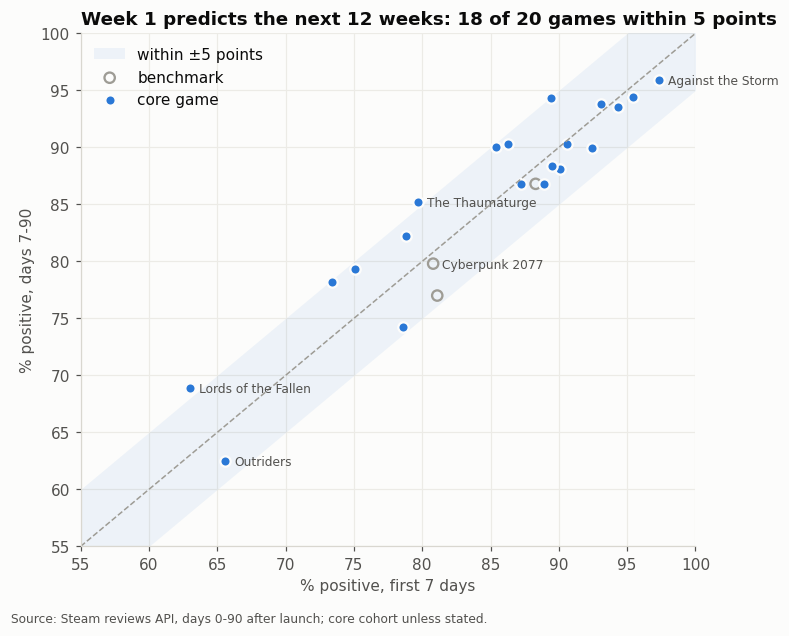

In [3]:
core = w1[w1.cohort == "core"]
x, y = core.pct_week1.to_numpy(), core.pct_days7_90.to_numpy()
rng = np.random.default_rng(42)
boot = rng.integers(0, len(x), (10_000, len(x)))
r_ci = np.percentile([np.corrcoef(x[i], y[i])[0, 1] for i in boot], [2.5, 97.5])
mae = np.abs(y - x).mean()
mae_ci = np.percentile(np.abs(y[boot] - x[boot]).mean(axis=1), [2.5, 97.5])
drift_ci = np.percentile((y[boot] - x[boot]).mean(axis=1), [2.5, 97.5])
loo_mean = (y.sum() - y) / (len(y) - 1)          # naive guess: the average of the other games
baseline_mae = np.abs(y - loo_mean).mean()

print(f"Within 5 points: {(np.abs(y - x) <= 5).sum()} of {len(x)} core games")
print(f"Correlation r = {np.corrcoef(x, y)[0, 1]:.2f} (95% bootstrap CI {r_ci[0]:.2f}-{r_ci[1]:.2f})")
print(f"Mean absolute error of week 1 as a forecast: {mae:.2f} points (CI {mae_ci[0]:.2f}-{mae_ci[1]:.2f})")
print(f"Naive forecast (average of the other games): {baseline_mae:.2f} points")
print(f"Average change after week 1: {(y - x).mean():+.2f} points (CI {drift_ci[0]:+.2f} to {drift_ci[1]:+.2f})")

fig, ax = plt.subplots(figsize=(7.2, 5.6))
lims = (55, 100)
ax.fill_between(lims, [l - 5 for l in lims], [l + 5 for l in lims], color=ACCENT, alpha=0.07, lw=0,
                label="within ±5 points")
ax.plot(lims, lims, color=GREY, lw=1, ls="--")
bench = w1[w1.cohort == "benchmark"]
ax.scatter(bench.pct_week1, bench.pct_days7_90, s=46, facecolor="none", edgecolor=GREY, lw=1.5, label="benchmark")
ax.scatter(core.pct_week1, core.pct_days7_90, s=46, color=ACCENT, edgecolor="#fcfcfb", lw=1.5, label="core game")
for _, r in w1.iterrows():
    if abs(r.change_week1_to_later) > 5 or r.game in ("Cyberpunk 2077", "Outriders", "Against the Storm"):
        ax.annotate(r.game, (r.pct_week1, r.pct_days7_90), xytext=(6, -3), textcoords="offset points",
                    fontsize=8, color=MUTED)
ax.set(xlim=lims, ylim=lims, xlabel="% positive, first 7 days", ylabel="% positive, days 7-90")
ax.set_title(f"Week 1 predicts the next 12 weeks: {(np.abs(y - x) <= 5).sum()} of 20 games within 5 points")
ax.legend(loc="upper left")
finish(fig, "q1_week1_vs_later")

### How early can you tell?

The same forecast from fewer days of reviews. The target stays fixed (reviews from days 7-90), so every checkpoint is tested on reviews it has not seen.

,days of reviews,mean error,worst game,within 5 points,median reviews so far
0,1,5.1,25.8,14,239
1,2,2.9,8.9,17,632
2,3,3.0,8.6,16,1051
3,4,2.8,7.6,15,1381
4,5,2.8,6.9,17,1756
5,6,2.9,6.2,16,2115
6,7,2.8,5.9,18,2393


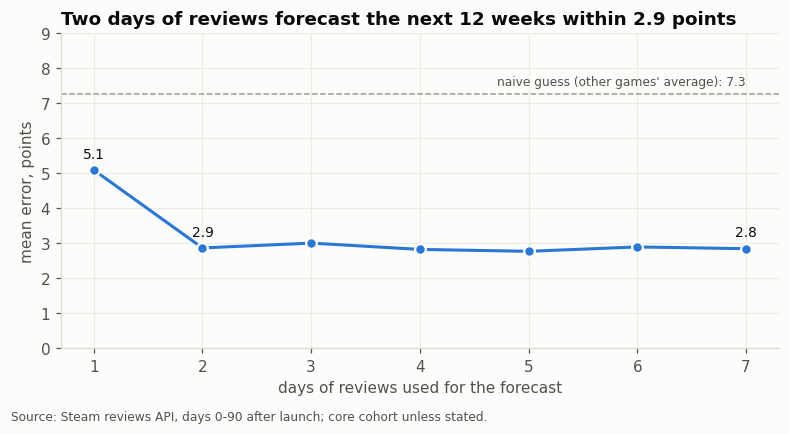

In [4]:
later = (daily[daily.day_n >= 7].groupby("app_id")[["positive", "reviews"]].sum()
         .eval("100 * positive / reviews").rename("later"))
rows = []
for day in range(0, 7):
    cum = daily[daily.day_n == day].set_index("app_id")
    err = (cum.pct_positive_cum - later).loc[list(core_ids)].abs()
    rows.append({"days of reviews": day + 1, "mean error": err.mean(), "worst game": err.max(),
                 "within 5 points": int((err <= 5).sum()),
                 "median reviews so far": int(cum.cum_reviews.loc[list(core_ids)].median())})
checkpoints = pd.DataFrame(rows)
display(checkpoints.round(1))

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.axhline(baseline_mae, color=GREY, lw=1, ls="--")
ax.text(7, baseline_mae + 0.25, f"naive guess (other games' average): {baseline_mae:.1f}", color=MUTED,
        fontsize=8, ha="right")
ax.plot(checkpoints["days of reviews"], checkpoints["mean error"], color=ACCENT, lw=2, marker="o", ms=7,
        mec="#fcfcfb", mew=1.5)
for _, r in checkpoints.iloc[[0, 1, 6]].iterrows():
    ax.annotate(f"{r['mean error']:.1f}", (r["days of reviews"], r["mean error"]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=9)
ax.set(ylim=(0, 9), xlabel="days of reviews used for the forecast", ylabel="mean error, points",
       xticks=range(1, 8))
ax.set_title(f"Two days of reviews forecast the next 12 weeks within {checkpoints['mean error'][1]:.1f} points")
finish(fig, "q1_how_early")

### Does week 1 also predict the *recent* score?

Steam's store page shows two scores: the overall one and **Recent Reviews** (the last 30 days). Because most reviews arrive in the first weeks, the overall score is dominated by them. The stricter test: week 1 against **days 61-90 only**, the "recent" score a player would see at the end of the quarter.

Within 5 points: 11 of 20; fell >5: 5, rose >5: 4
Mean error 5.3 points (naive guess 10.0); average change +0.1


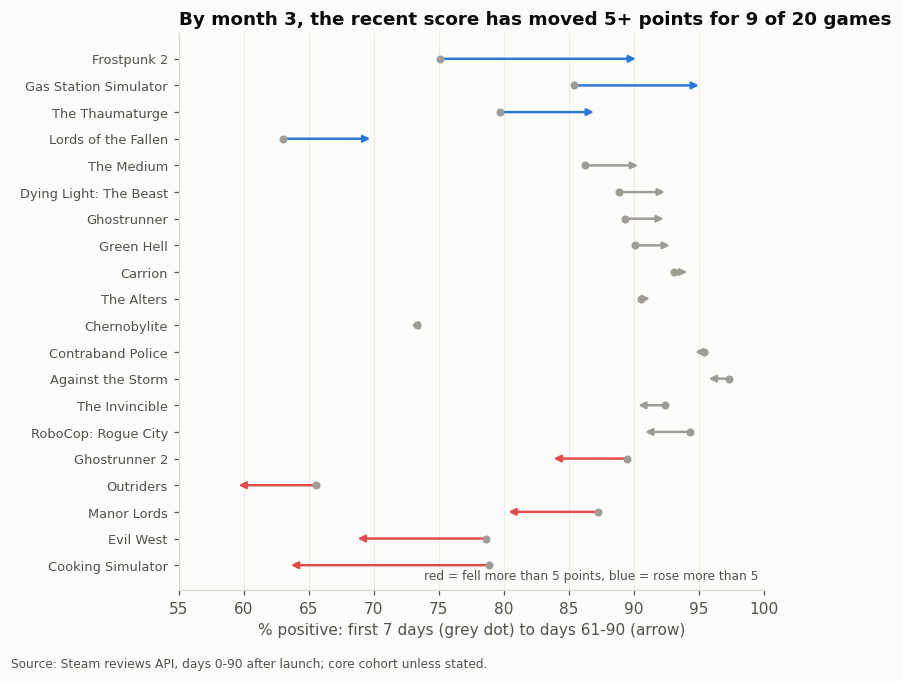

In [5]:
def window_pct(lo, hi):
    x = daily[daily.day_n.between(lo, hi)].groupby("app_id")[["positive", "reviews"]].sum()
    return 100 * x.positive / x.reviews

recent = (pd.DataFrame({"week1": window_pct(0, 6), "days61_90": window_pct(61, 90)})
          .join(games.set_index("app_id")[["game", "cohort"]]).query("cohort == 'core'"))
recent["change"] = recent.days61_90 - recent.week1
rc = recent.change
rloo = (recent.days61_90.sum() - recent.days61_90) / (len(recent) - 1)
print(f"Within 5 points: {(rc.abs() <= 5).sum()} of {len(rc)}; fell >5: {(rc < -5).sum()}, rose >5: {(rc > 5).sum()}")
print(f"Mean error {rc.abs().mean():.1f} points (naive guess {(recent.days61_90 - rloo).abs().mean():.1f}); "
      f"average change {rc.mean():+.1f}")

r_ = recent.sort_values("change")
fig, ax = plt.subplots(figsize=(7.2, 6.0))
for i, r in enumerate(r_.itertuples()):
    c = RED if r.change < -5 else ACCENT if r.change > 5 else GREY
    ax.annotate("", xy=(r.days61_90, i), xytext=(r.week1, i),
                arrowprops=dict(arrowstyle="-|>", color=c, lw=1.6, shrinkA=0, shrinkB=0, mutation_scale=9))
    ax.scatter(r.week1, i, s=18, color=GREY, zorder=3)
ax.set_yticks(range(len(r_)), r_.game, fontsize=8.5)
ax.set(xlabel="% positive: first 7 days (grey dot) to days 61-90 (arrow)", xlim=(55, 100))
ax.grid(axis="y", visible=False)
ax.text(0.99, 0.02, "red = fell more than 5 points, blue = rose more than 5", transform=ax.transAxes,
        ha="right", fontsize=8, color=MUTED)
ax.set_title(f"By month 3, the recent score has moved 5+ points for {(rc.abs() > 5).sum()} of 20 games")
finish(fig, "q1_recent_score")

**Reading:** two different answers, and both matter.

- **The overall rating is set almost immediately.** After two days, a game's score is on average within about 3 points of everything written in the rest of the quarter, less than half the error of a naive guess, with no systematic drift. Day 1 alone is not enough: with a few hundred reviews, the worst game misses by more than 20 points.
- **The recent score is not locked in.** By days 61-90 the 30-day score has moved more than 5 points for almost half the core games, in both directions (Frostpunk 2 up 15 points, Cooking Simulator and Evil West down 10+). The overall score hides these moves because late reviews are few. A rating going wrong after launch shows up first as the rolling score pulling away from the overall score (see the Cyberpunk spotlight).

## 2. First impression or content problem?

Playtime at review splits negative reviews into those written inside Steam's refund window (**under 2 hours**: performance, onboarding, expectations) and those from players who stayed (**20+ hours**: content, endgame, balance).

,playtime_bucket,reviews,pct_positive,pct_negatives_refunded
0,0-2h,25225,65.1,14.1
1,2-5h,45705,84.0,3.9
3,5-20h,126899,85.5,0.1
2,20h+,91261,81.2,0.1


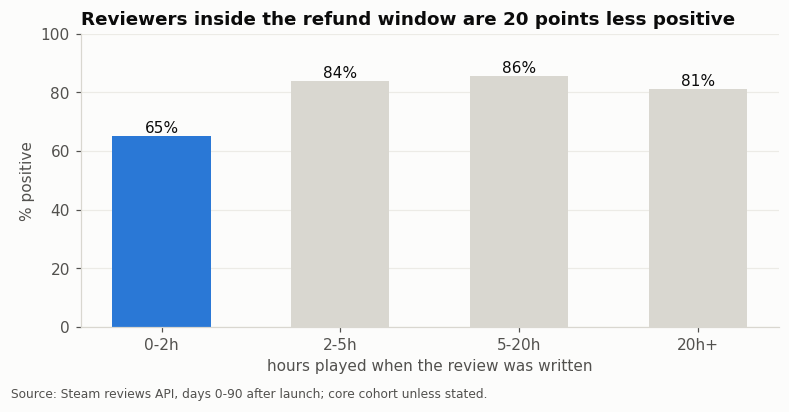

In [6]:
pb = views["v_playtime_buckets"]
pb_core = pb[pb.cohort == "core"]
by_bucket = (pb_core.groupby(["playtime_bucket", "playtime_bucket_order"])[["reviews", "negatives", "negatives_refunded"]]
             .sum().reset_index().sort_values("playtime_bucket_order"))
by_bucket["pct_positive"] = 100 * (1 - by_bucket.negatives / by_bucket.reviews)
by_bucket["pct_negatives_refunded"] = 100 * by_bucket.negatives_refunded / by_bucket.negatives
display(by_bucket[["playtime_bucket", "reviews", "pct_positive", "pct_negatives_refunded"]].round(1))

fig, ax = plt.subplots(figsize=(7.2, 3.6))
colors = [ACCENT if b == "0-2h" else LIGHT for b in by_bucket.playtime_bucket]
bars = ax.bar(by_bucket.playtime_bucket, by_bucket.pct_positive, color=colors, width=0.55)
for b, v in zip(bars, by_bucket.pct_positive):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.2, f"{v:.0f}%", ha="center", fontsize=10)
ax.set(ylim=(0, 100), ylabel="% positive", xlabel="hours played when the review was written")
ax.grid(axis="x", visible=False)
gap = by_bucket.pct_positive.iloc[1:3].mean() - by_bucket.pct_positive.iloc[0]
ax.set_title(f"Reviewers inside the refund window are {gap:.0f} points less positive")
finish(fig, "q2_playtime")

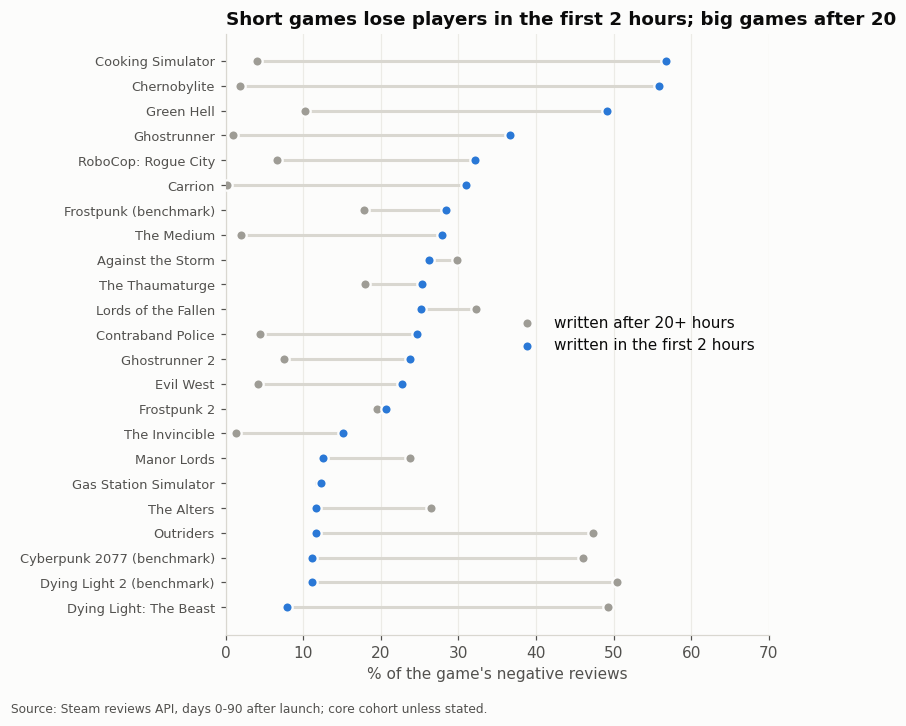

Spearman correlation, typical playtime of positive reviewers vs share of 20h+ negatives: 0.91


In [7]:
prof = views["v_negative_profile"].sort_values("pct_neg_under_2h")
fig, ax = plt.subplots(figsize=(7.2, 6.4))
yy = np.arange(len(prof))
ax.hlines(yy, prof[["pct_neg_under_2h", "pct_neg_20h_plus"]].min(axis=1),
          prof[["pct_neg_under_2h", "pct_neg_20h_plus"]].max(axis=1), color=LIGHT, lw=2)
ax.scatter(prof.pct_neg_20h_plus, yy, s=46, color=GREY, edgecolor="#fcfcfb", lw=1.5, label="written after 20+ hours", zorder=3)
ax.scatter(prof.pct_neg_under_2h, yy, s=46, color=ACCENT, edgecolor="#fcfcfb", lw=1.5, label="written in the first 2 hours", zorder=3)
ax.set_yticks(yy, [f"{g}{' (benchmark)' if c == 'benchmark' else ''}" for g, c in zip(prof.game, prof.cohort)], fontsize=8.5)
ax.set(xlim=(0, 70), xlabel="% of the game's negative reviews")
ax.grid(axis="y", visible=False)
ax.legend(loc="center right")
ax.set_title("Short games lose players in the first 2 hours; big games after 20")
finish(fig, "q2_negative_profile")

rho = prof[["median_hours_positive", "pct_neg_20h_plus"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation, typical playtime of positive reviewers vs share of 20h+ negatives: {rho:.2f}")

**Reading:** players who review inside the refund window are by far the unhappiest group, and they are the ones who can still get their money back. For Cooking Simulator, Chernobylite and Green Hell about half of all negative reviews are written in the first two hours. Big, long games (Outriders, Dying Light, Cyberpunk) are the reverse: around half of their negatives come from players with 20+ hours.

**Caveat:** part of this split is game length. A short game cannot collect many 20-hour reviews, and the correlation above shows how strongly the 20h+ share follows typical playtime. So "first impression vs content" is best read within a game type, not as a ranking across all 23.

## 3. Which markets are unhappy?

Each review language is compared with the game's own overall score (**gap**, in points), so a market is judged against the same game rather than against other games. Only markets with 50+ reviews for a game are used.

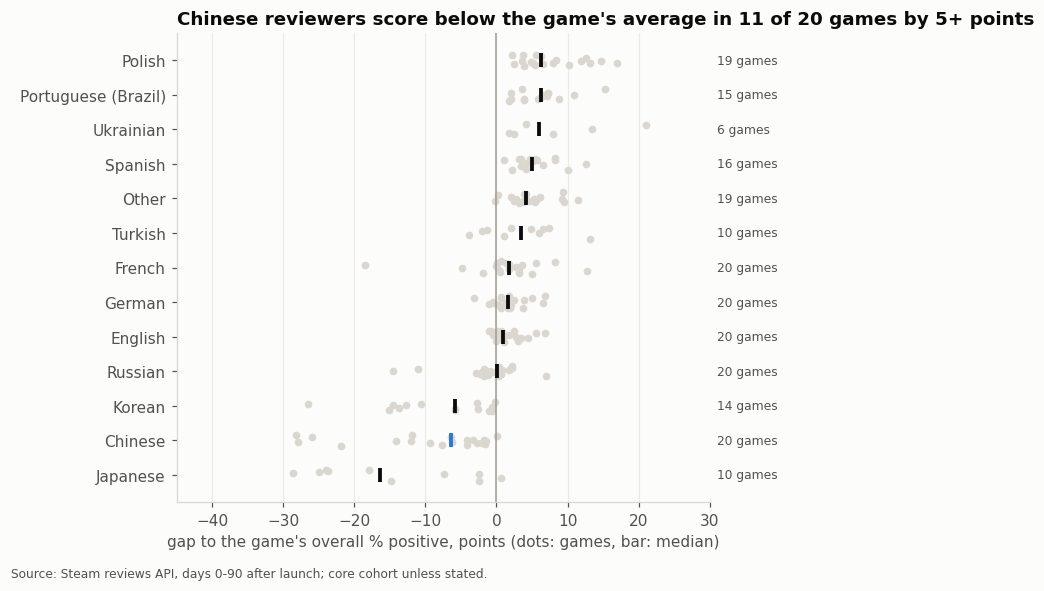

,market,core_games_with_50_reviews,reviews,median_gap_points,games_more_than_5_below,excess_negatives
0,Chinese,20,46488,-6.4,11,6545
5,Korean,14,4727,-5.9,8,434
4,Japanese,10,1428,-16.4,7,249
9,Russian,20,23963,0.1,2,-41
12,Ukrainian,6,1626,6.0,0,-106
11,Turkish,10,4753,3.5,0,-187


,game,market,reviews,pct_positive,game_pct_positive,gap_points,excess_negatives
195,Manor Lords,Chinese,6191,59.2,87.1,-27.9,1727
208,Lords of the Fallen,Chinese,5437,39.8,65.7,-25.9,1410
39,Outriders,Chinese,4095,35.9,64.0,-28.2,1153
286,Dying Light: The Beast,Chinese,11664,78.4,87.8,-9.4,1093
234,Frostpunk 2,Chinese,3763,65.1,77.1,-12.0,451
143,Ghostrunner,Chinese,4745,89.1,92.4,-3.3,159


In [8]:
ls = views["v_language_score"]
ls_core = ls[(ls.cohort == "core") & ls.reliable]
order = ls_core.groupby("market").gap_points.median().sort_values()
fig, ax = plt.subplots(figsize=(7.2, 5.2))
for i, m in enumerate(order.index):
    pts = ls_core[ls_core.market == m].gap_points
    jitter = np.random.default_rng(i).uniform(-0.18, 0.18, len(pts))
    ax.scatter(pts, i + jitter, s=16, color=LIGHT, zorder=2)
    c = ACCENT if m == "Chinese" else INK
    ax.scatter(order[m], i, s=90, marker="|", color=c, lw=2.5, zorder=3)
    ax.text(31, i, f"{len(pts)} games", va="center", fontsize=8, color=MUTED)
ax.axvline(0, color=GREY, lw=1)
ax.set_yticks(range(len(order)), order.index)
ax.set(xlim=(-45, 30), xlabel="gap to the game's overall % positive, points (dots: games, bar: median)")
ax.grid(axis="y", visible=False)
cn_pts = ls_core[ls_core.market == "Chinese"].gap_points
ax.set_title(f"Chinese reviewers score below the game's average in {(cn_pts < -5).sum()} of {len(cn_pts)} games by 5+ points")
finish(fig, "q3_markets")

ms = views["v_market_summary"].sort_values("excess_negatives", ascending=False)
display(ms[["market", "core_games_with_50_reviews", "reviews", "median_gap_points",
            "games_more_than_5_below", "excess_negatives"]].head(6))
display(ls_core.sort_values("excess_negatives", ascending=False)
        [["game", "market", "reviews", "pct_positive", "game_pct_positive", "gap_points", "excess_negatives"]].head(6))

**Reading:** Chinese is the one large market that is consistently unhappier than the rest: it scores more than 5 points below the game's average in more than half of the core games, and produces several thousand more negative reviews than each game's overall rate would predict, by far the largest total. Japanese reviewers have the lowest median gap and Korean reviewers lean negative too, but on far smaller volumes (see the excess-negatives table). Polish players are the most positive of all, a home-market effect.

Section 4 tests the obvious explanation (poor translation) and finds it does not hold.

## 4. What do players complain about?

Negative reviews are tagged with keyword themes: English and Polish keywords for one group, Chinese keywords for the other. The groups are compared over time and in their **mix**, never pooled, because different keyword lists catch different amounts. A review can mention several themes; keyword matching misses sarcasm and synonyms, so the shares are indicative.

period                                            week 1  days 7-29  \
text_group     theme_order theme                                      
Chinese        1           performance & crashes    26.0       19.5   
               2           bugs                     18.1       21.4   
               3           price & value            10.3       10.6   
               4           length & content          6.8        8.5   
               5           story & writing           9.4       16.3   
               6           servers & online         12.0        7.8   
               7           translation               2.3        1.2   
English/Polish 1           performance & crashes    30.2       26.6   
               2           bugs                     24.2       31.3   
               3           price & value            23.8       23.3   
               4           length & content         18.3       24.9   
               5           story & writing          20.9       27.8   
               6           servers & online         23.3       16.1   
               7           translation               0.6        0.7   

period                                            days 30-90  
text_group     theme_order theme                              
Chinese        1           performance & crashes        15.6  
               2           bugs                         15.1  
               3           price & value                11.2  
               4           length & content              9.9  
               5           story & writing              15.3  
               6           servers & online              4.4  
               7           translation                   1.4  
English/Polish 1           performance & crashes        20.7  
               2           bugs                         27.7  
               3           price & value                21.9  
               4           length & content             26.2  
               5           story & writing              25.9  
               6           servers & online             10.4  
               7           translation                   0.5

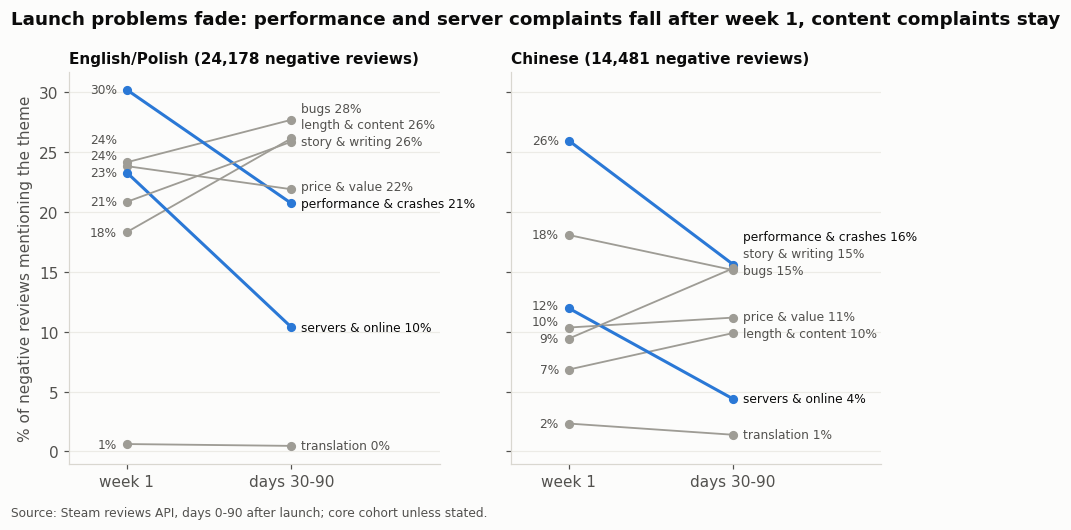

In [9]:
tp = views["v_theme_by_period"]
tp_core = tp[tp.cohort == "core"]
shares = (tp_core.groupby(["text_group", "theme", "theme_order", "period", "period_order"])[["mentions", "negatives_analysed"]]
          .sum().reset_index().assign(pct=lambda d: 100 * d.mentions / d.negatives_analysed))
wide = shares.pivot_table(index=["text_group", "theme_order", "theme"], columns="period", values="pct")[
    ["week 1", "days 7-29", "days 30-90"]].round(1)
display(wide)

fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.6), sharey=True)
falling = {"performance & crashes", "servers & online"}
for ax, group in zip(axes, ["English/Polish", "Chinese"]):
    g = shares[(shares.text_group == group) & shares.period.isin(["week 1", "days 30-90"])]
    lines = [(theme, t.sort_values("period_order").pct.to_numpy()) for theme, t in g.groupby("theme")]
    right = repel([v[-1] for _, v in lines], 1.4)
    left = repel([v[0] for _, v in lines], 1.4)
    for (theme, v), yr, yl in zip(lines, right, left):
        c = ACCENT if theme in falling else GREY
        ax.plot([0, 1], v, color=c, lw=2 if theme in falling else 1.2, marker="o", ms=5)
        ax.text(1.06, yr, f"{theme} {v[-1]:.0f}%", va="center", fontsize=8, color=INK if theme in falling else MUTED)
        ax.text(-0.06, yl, f"{v[0]:.0f}%", va="center", ha="right", fontsize=8, color=MUTED)
    n = tp_core[tp_core.text_group == group].drop_duplicates(["app_id", "period"]).negatives_analysed.sum()
    ax.set_title(f"{group} ({n:,} negative reviews)", fontsize=10)
    ax.set_xticks([0, 1], ["week 1", "days 30-90"])
    ax.set_xlim(-0.35, 1.9)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% of negative reviews mentioning the theme")
fig.suptitle("Launch problems fade: performance and server complaints fall after week 1, content complaints stay",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
finish(fig, "q4_themes")

In [10]:
zh_translation = tp_core[(tp_core.text_group == "Chinese") & (tp_core.theme == "translation")]
zh_t = 100 * zh_translation.mentions.sum() / zh_translation.negatives_analysed.sum()
print(f"Translation is mentioned in {zh_t:.1f}% of Chinese negative reviews (core games).")

Translation is mentioned in 1.9% of Chinese negative reviews (core games).


**Reading:** in both groups, the share of negatives about performance and servers falls sharply between week 1 and days 30-90, while content and story complaints hold or grow. The launch-specific problems get fixed (or the players they hit have left); what remains are complaints about the game itself.

**Translation explains almost none of the Chinese gap** from section 3: it appears in only a few percent of Chinese negative reviews. Performance is the largest theme for Chinese players too. One game-specific exception worth knowing: for Manor Lords, a noticeable share of Chinese negatives attack the publisher for giving streamers two weeks of early play.

### Does the first major patch change the score?

For each game, the first major patch was picked by hand from its official Steam announcements (choices documented in the README). The comparison is 14 days before vs 14 days after, excluding the patch day. Scores also drift naturally after launch, so this is a before/after comparison, not proof of cause.

Score after the first major patch: up in 11, down in 12 of 23 games (median change -0.2 points)
Share of negatives about performance fell in 15 of 23 games


C:\Users\TUTU\AppData\Local\Temp\ipykernel_22844\3795645222.py:1: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  pe = views["v_patch_effect"].query("reliable").sort_values("change_points")


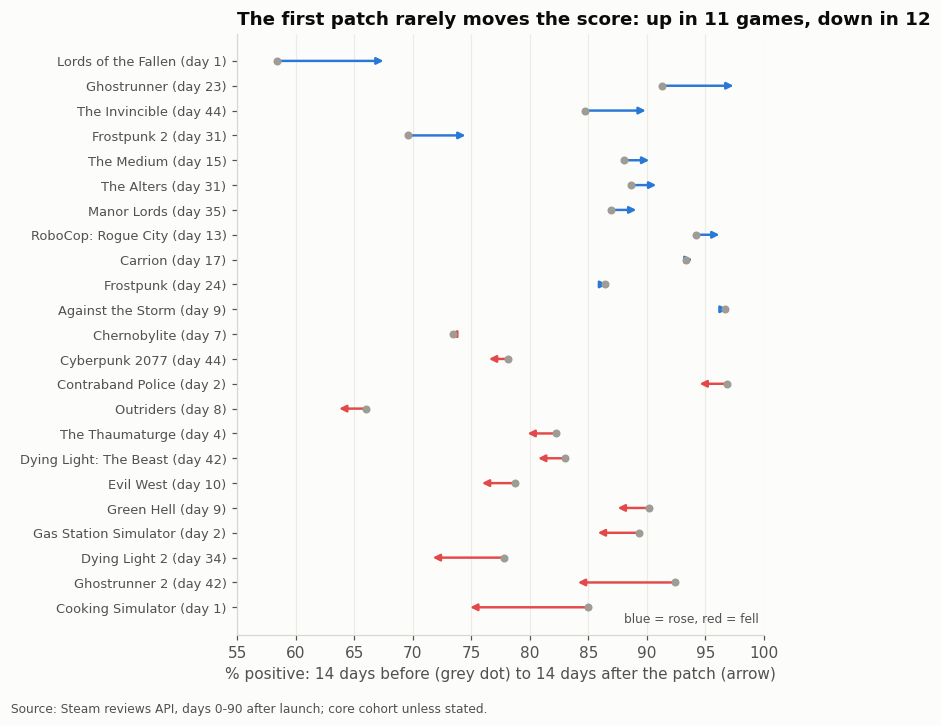

In [11]:
pe = views["v_patch_effect"].query("reliable").sort_values("change_points")
up, down = (pe.change_points > 0).sum(), (pe.change_points < 0).sum()
perf_down = (pe.pct_neg_performance_after < pe.pct_neg_performance_before).sum()
print(f"Score after the first major patch: up in {up}, down in {down} of {len(pe)} games "
      f"(median change {pe.change_points.median():+.1f} points)")
print(f"Share of negatives about performance fell in {perf_down} of {len(pe)} games")

fig, ax = plt.subplots(figsize=(7.2, 6.4))
yy = np.arange(len(pe))
for i, r in enumerate(pe.itertuples()):
    c = ACCENT if r.change_points > 0 else RED
    ax.annotate("", xy=(r.pct_positive_after, i), xytext=(r.pct_positive_before, i),
                arrowprops=dict(arrowstyle="-|>", color=c, lw=1.6, shrinkA=0, shrinkB=0, mutation_scale=9))
    ax.scatter(r.pct_positive_before, i, s=18, color=GREY, zorder=3)
ax.set_yticks(yy, [f"{g} (day {d})" for g, d in zip(pe.game, pe.patch_day)], fontsize=8.5)
ax.set(xlabel="% positive: 14 days before (grey dot) to 14 days after the patch (arrow)", xlim=(55, 100))
ax.grid(axis="y", visible=False)
ax.text(0.99, 0.02, "blue = rose, red = fell", transform=ax.transAxes, ha="right", fontsize=8, color=MUTED)
ax.set_title(f"The first patch rarely moves the score: up in {up} games, down in {down}")
finish(fig, "q4_patch_effect")

**Reading:** the first major patch is not a reliable way to lift a rating: about as many games fell as rose after it, and the typical change is close to zero. It does tend to change *what* people complain about, with performance complaints falling in most games. The clearest positive case, Lords of the Fallen, patched on day 1 and gained about 9 points in the following two weeks; it is also one of the two games whose score improved after week 1 in section 1.

## Spotlight: Cyberpunk 2077 on Steam

Cyberpunk 2077 is remembered for one of the worst launches in recent history, so it was chosen as the benchmark for "a rating going wrong". Its Steam PC reviews tell a quieter version of that story, and show why the overall score is the wrong place to look for it.

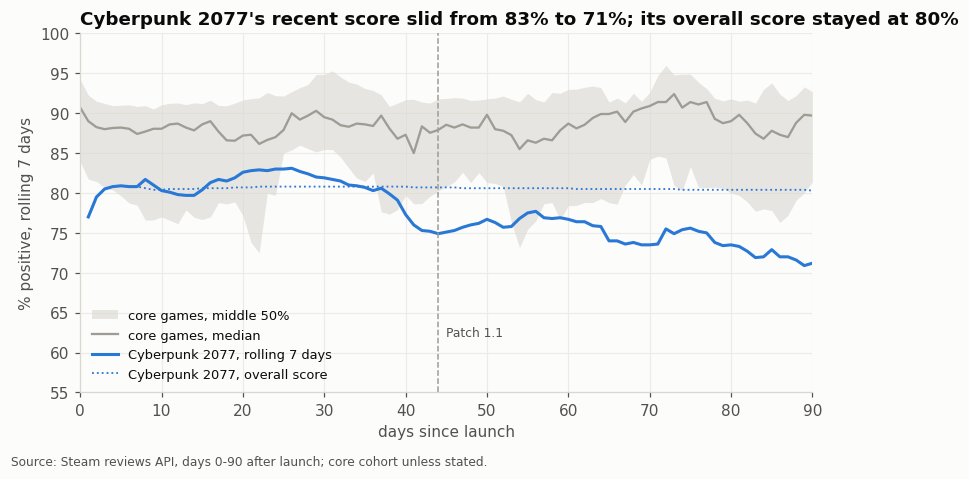

Week 1: 80.8%  |  days 7-90: 79.8%  |  368,882 reviews in 90 days
46.1% of its negative reviews came after 20+ hours; 11.2% within 2 hours


,market,reviews,pct_positive,gap_points
135,Korean,10213,63.0,-17.4
130,Chinese,108944,72.5,-7.9
134,Japanese,987,77.6,-2.7
138,Portuguese (Brazil),9724,81.7,1.3


In [12]:
cp_id = games.loc[games.game == "Cyberpunk 2077", "app_id"].iloc[0]
band = (daily[daily.app_id.isin(core_ids) & daily.r7_reliable].groupby("day_n").pct_positive_7d
        .quantile([0.25, 0.5, 0.75]).unstack())
cp = daily[daily.app_id == cp_id]
patch = views["v_first_patch"].set_index("app_id").loc[cp_id]

fig, ax = plt.subplots(figsize=(7.6, 4.2))
ax.fill_between(band.index, band[0.25], band[0.75], color=LIGHT, alpha=0.6, lw=0, label="core games, middle 50%")
ax.plot(band.index, band[0.5], color=GREY, lw=1.5, label="core games, median")
ax.plot(cp.day_n, cp.pct_positive_7d, color=ACCENT, lw=2, label="Cyberpunk 2077, rolling 7 days")
ax.axvline(patch.patch_day, color=GREY, lw=1, ls="--")
ax.text(patch.patch_day + 1, 62, patch.patch_title, fontsize=8, color=MUTED)
ax.set(xlim=(0, 90), ylim=(55, 100), xlabel="days since launch", ylabel="% positive, rolling 7 days")
ax.legend(loc="lower right")
cp_peak = cp[cp.day_n.between(7, 45)].pct_positive_7d.max()
cp_end = cp.loc[cp.day_n == 90, "pct_positive_7d"].iloc[0]
cp_cum = cp.loc[cp.day_n == 90, "pct_positive_cum"].iloc[0]
ax.plot(cp.day_n, cp.pct_positive_cum, color=ACCENT, lw=1.2, ls=":", label="Cyberpunk 2077, overall score")
ax.legend(loc="lower left", fontsize=8.5)
ax.set_title(f"Cyberpunk 2077's recent score slid from {cp_peak:.0f}% to {cp_end:.0f}%; its overall score stayed at {cp_cum:.0f}%")
finish(fig, "spotlight_cyberpunk")

cp_row = w1.set_index("app_id").loc[cp_id]
cp_prof = views["v_negative_profile"].set_index("app_id").loc[cp_id]
cp_mk = ls[(ls.app_id == cp_id) & ls.reliable].sort_values("gap_points")[["market", "reviews", "pct_positive", "gap_points"]]
print(f"Week 1: {cp_row.pct_week1}%  |  days 7-90: {cp_row.pct_days7_90}%  |  {cp_row.reviews_day90:,} reviews in 90 days")
print(f"{cp_prof.pct_neg_20h_plus}% of its negative reviews came after 20+ hours; {cp_prof.pct_neg_under_2h}% within 2 hours")
display(cp_mk.head(4))

**Reading:** Cyberpunk 2077's overall Steam score barely moved in 90 days, because more than half of its reviews were written in week 1. Underneath it, the rolling score peaked in the first month and then slid by about 10 points, below the core games' band, and Patch 1.1 did not stop the slide. That is exactly the warning a publisher would miss by watching only the headline score.

The PC reviews also show a *content* profile: most negatives came from players with 20+ hours, not from people who bounced off in the refund window. (The well-known launch crisis was mostly on consoles, which Steam reviews do not cover: a platform's reviews only describe that platform's players.)

## Three findings

In [13]:
two_day = checkpoints["mean error"][1]
cn = views["v_market_summary"].set_index("market").loc["Chinese"]
top3 = views["v_negative_profile"].query("cohort == 'core'").nlargest(3, "pct_neg_under_2h")
findings = [
    f"1. A game's overall Steam score is set within two days: the first two days forecast the rest of the quarter "
    f"within {two_day:.1f} points on average (a naive guess is off by {baseline_mae:.1f}). The recent score is not: "
    f"by days 61-90 it had moved 5+ points for {(rc.abs() > 5).sum()} of 20 core games.",
    f"2. Reviewers inside the 2-hour refund window are {gap:.0f} points less positive than players with 2-20 hours; "
    f"for {', '.join(top3.game)} they wrote {top3.pct_neg_under_2h.min():.0f}-{top3.pct_neg_under_2h.max():.0f}% "
    f"of all negative reviews.",
    f"3. Chinese reviewers score a median {abs(cn.median_gap_points):.1f} points below the same game's average "
    f"({int(cn.games_more_than_5_below)} of {int(cn.core_games_with_50_reviews)} core games more than 5 points below), "
    f"and translation explains almost none of it ({zh_t:.1f}% of Chinese negatives mention it).",
]
print("\n\n".join(findings))

1. A game's overall Steam score is set within two days: the first two days forecast the rest of the quarter within 2.9 points on average (a naive guess is off by 7.3). The recent score is not: by days 61-90 it had moved 5+ points for 9 of 20 core games.

2. Reviewers inside the 2-hour refund window are 20 points less positive than players with 2-20 hours; for Cooking Simulator, Chernobylite, Green Hell they wrote 49-57% of all negative reviews.

3. Chinese reviewers score a median 6.4 points below the same game's average (11 of 20 core games more than 5 points below), and translation explains almost none of it (1.9% of Chinese negatives mention it).


## Recommendations for the head of publishing

1. **Read the overall score on day 2, then watch the rolling score.** By the end of the second day the headline rating is within a few points of where it will sit for the quarter, so the response plan (hotfix, communication, price or key strategy) should be ready before launch and start on day 2. After week 1, track the rolling 7-day score against the overall score: when it pulls away, as Cyberpunk's did, the rating is going wrong even though the headline number has not moved.
2. **Treat the first two hours as part of the launch.** Performance, onboarding and expectation-setting decide the refund-window reviews, the unhappiest group. Test the first session on minimum-spec hardware and make the store page set honest expectations.
3. **Make China a launch priority, and look past translation.** The gap is large and consistent, and it is not mainly about language: performance complaints lead there too. Hardware coverage for the Chinese market, region-specific community management and launch communication on Chinese platforms are the levers to test.
4. **Do not count on the first patch to repair the rating.** It changes what people complain about, but in this sample it did not reliably move the score. Fix before launch where possible.

## Limitations

- **Steam only, PC only.** Console launches (see the Cyberpunk spotlight) are invisible here.
- **Today's verdicts.** About 20% of reviews were edited after they were written; edited reviews are more negative than unedited ones, so launch scores are, if anything, slightly understated.
- **Keyword themes are indicative.** The Chinese keywords match a smaller share of reviews (56% vs 72%), so about half of Chinese negatives stay untagged.
- **Small sample of games.** 20 core games: the confidence intervals above are wide, and the findings describe this cohort of Polish studios, not every Steam launch.
- **Patch effects are before/after comparisons,** not causal estimates; patch picks are judgment calls, documented in the README.